In [15]:

import polars as pl
fcs= pl.read_parquet("forecast_result.parquet")
daa = pl.read_parquet("daa_price.parquet")
daa = daa.select(pl.col("delivery_start").dt.convert_time_zone("UTC"),pl.col("daa_price"))

result =(
    daa
    .join(fcs, on="delivery_start", how="full",coalesce=True)

) 
print("DAA Prices and Residual Load Forecast")
display(result)


DAA Prices and Residual Load Forecast


delivery_start,daa_price,entsoe,enappsys,energy_weather,GFS_ENS,EC_OP,EC_46,GFS_OP,EC_AIFS,EC_ENS,EC_AIFS_ENS,tech_avail
"datetime[μs, UTC]",f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2026-01-01 00:00:00 UTC,60.01,8469.0,10310.0,null,6870.44,6489.05,10183.42,3739.45,8379.26,7036.98,null,-2660.471509
2026-01-01 00:15:00 UTC,48.9,7208.0,9457.0,null,6180.66,6216.17,10183.42,3088.67,7693.09,6318.96,null,-3729.071544
2026-01-01 00:30:00 UTC,36.74,6298.0,9083.0,null,5369.82,6189.5,10183.42,2499.47,6412.5,5401.69,null,-4641.857449
2026-01-01 00:45:00 UTC,23.93,5804.0,8311.0,null,4377.39,5455.32,10183.42,2295.28,6513.04,4935.19,null,-5460.320099
2026-01-01 01:00:00 UTC,36.01,4976.0,8055.0,null,3175.97,5328.14,7598.38,2008.71,5514.48,4834.84,null,-6194.019856
…,…,…,…,…,…,…,…,…,…,…,…,…
2026-08-31 23:15:00 UTC,146.05,null,null,null,null,null,null,null,null,null,null,17403.638161
2026-08-31 23:30:00 UTC,146.19,null,null,null,5529.26,11703.08,10376.89,5542.55,14044.53,8583.28,11692.38,null
2026-08-31 23:30:00 UTC,146.19,null,null,null,null,null,null,null,null,null,null,17548.877713


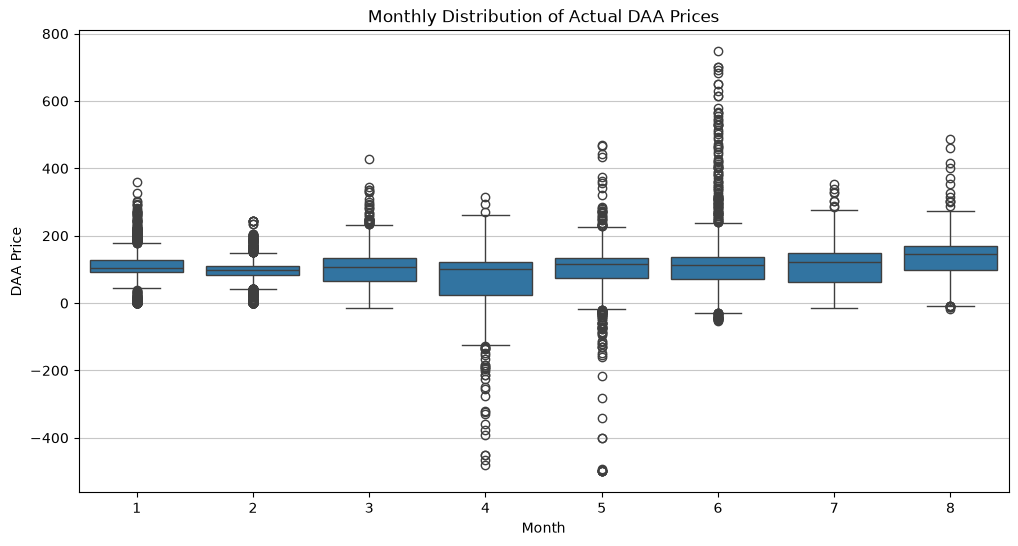

In [ ]:
# whis = 1.5 IQR = 1.5 * (Q3 - Q1)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plot_df = (
    result
    .select(["delivery_start", "daa_price"])
    .to_pandas()
)

plot_df["delivery_start"] = pd.to_datetime(plot_df["delivery_start"])
plot_df["month"] = plot_df["delivery_start"].dt.month

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=plot_df,
    x="month",
    y="daa_price"
)

plt.title("Monthly Distribution of Actual DAA Prices")
plt.xlabel("Month")
plt.ylabel("DAA Price")
plt.grid(axis="y", alpha=0.7)

plt.show()

In [16]:
#correlation between forecasts and daa_price
forecasts = result.columns[2:]

rows = []

for f in forecasts:
    corr = result.select(
        pl.corr(pl.col(f), pl.col("daa_price"))
    ).item()

    rows.append({
        "forecast": f,
        "corr_with_daa_price": round(corr, 3)
    })

corr_matrix = pl.DataFrame(rows).sort("corr_with_daa_price",descending= True)

display(corr_matrix)

forecast,corr_with_daa_price
str,f64
"""tech_avail""",0.825
"""energy_weather""",0.821
"""EC_46""",0.773
"""EC_ENS""",0.773
"""EC_OP""",0.772
…,…
"""EC_AIFS_ENS""",0.77
"""GFS_ENS""",0.763
"""GFS_OP""",0.759


ENTSOE - Number of observations: 17,264


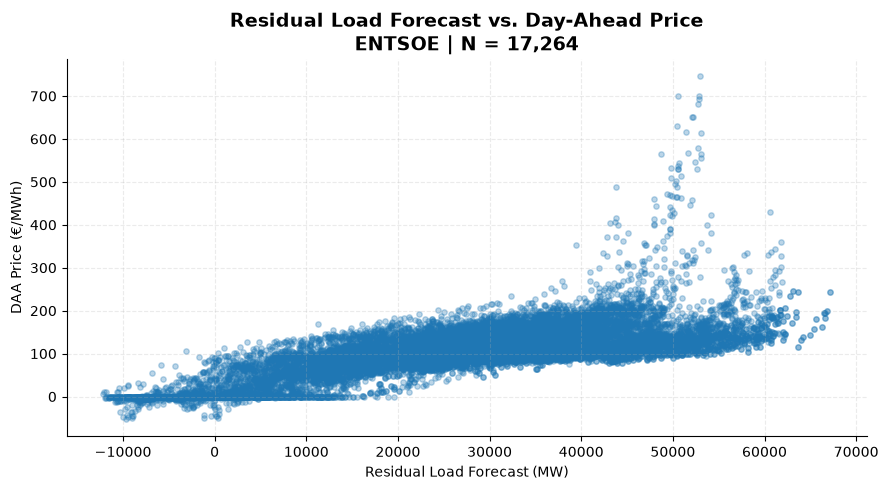

ENAPPSYS - Number of observations: 24,625


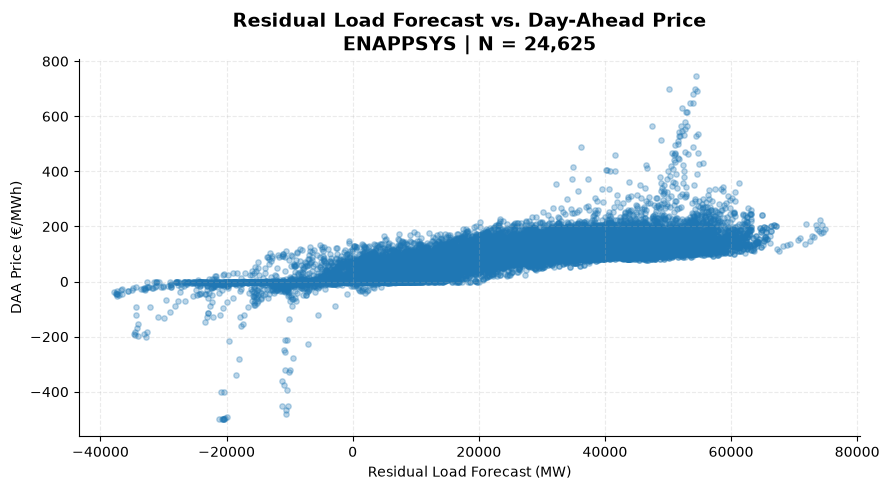

ENERGY_WEATHER - Number of observations: 19,304


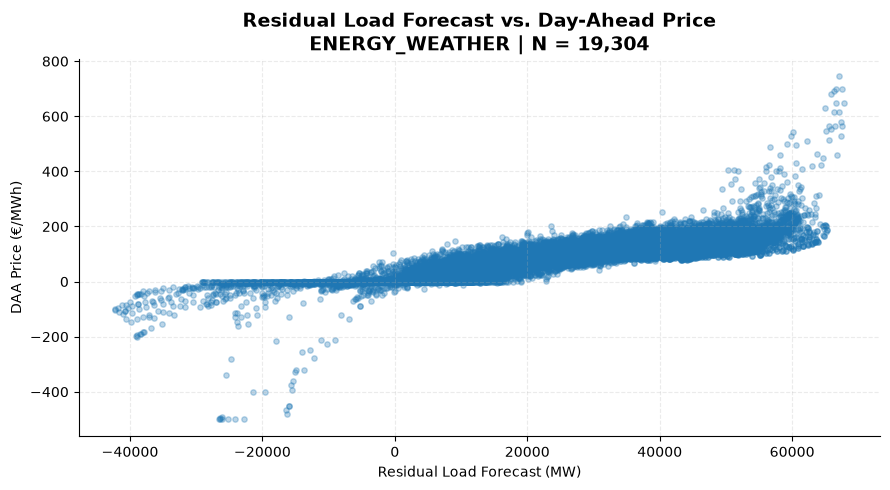

EC_ENS - Number of observations: 25,444


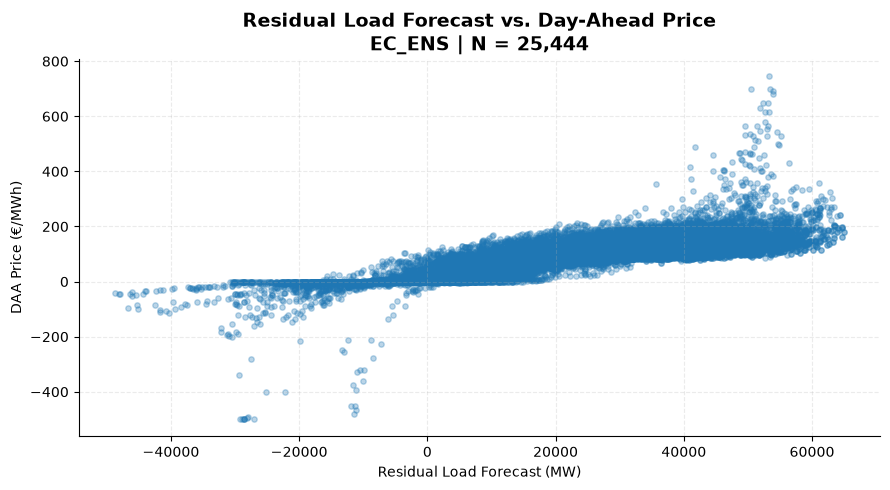

TECH_AVAIL - Number of observations: 25,444


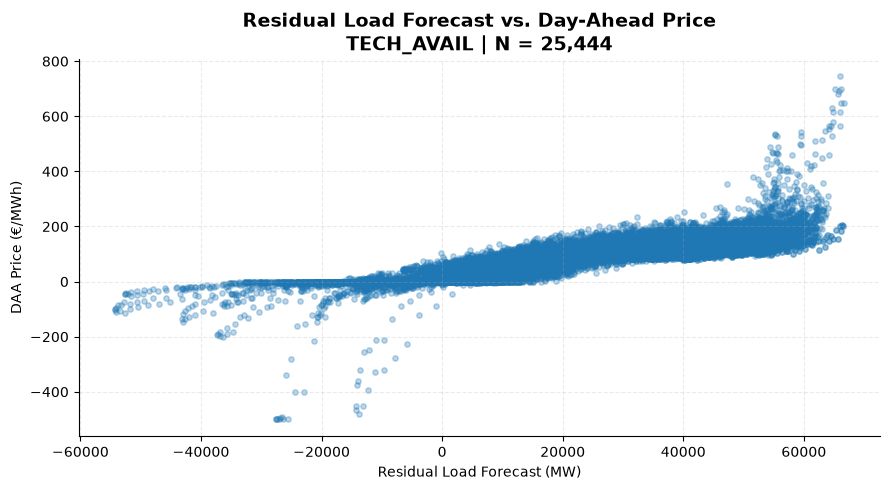

In [17]:
import matplotlib.pyplot as plt

providers = [
    "entsoe",
    "enappsys",
    "energy_weather",
    "EC_ENS",
    "tech_avail"
]

for provider in providers:

    clean = (
        result
        .select(["daa_price", provider])
        .drop_nulls()
    )

    # Number of observations used
    n = len(clean)

    print(f"{provider.upper()} - Number of observations: {n:,}")

    plt.figure(figsize=(9, 5))

    plt.scatter(
        clean[provider],
        clean["daa_price"],
        alpha=0.3,
        s=15
    )

    plt.title(
    f"Residual Load Forecast vs. Day-Ahead Price\n{provider.upper()} | N = {n:,}",
    fontsize=14,
    fontweight="bold"
)
    

    plt.xlabel("Residual Load Forecast (MW)")
    plt.ylabel("DAA Price (€/MWh)")

    plt.grid(alpha=0.25, linestyle="--")

    plt.gca().spines["top"].set_visible(False)
    plt.gca().spines["right"].set_visible(False)

    plt.tight_layout()
    plt.show()

In [18]:
import polars as pl
import pandas as pd
import statsmodels.formula.api as smf

df = result.with_columns(
    pl.col("delivery_start").dt.hour().alias("hour"),
    pl.col("delivery_start").dt.month().alias("month"),
    (pl.col("delivery_start").dt.weekday() >= 6)
        .cast(pl.Int8)
        .alias("weekend")
)

In [19]:
## analyse BY USING MULTIPLE REGRESSION (residual load, weekend dummny, month dummny, hour dummy) => adjusted R2, MSE, MAE 
import polars as pl
import statsmodels.formula.api as smf

# Add time variables
df = result.with_columns(
    pl.col("delivery_start").dt.hour().alias("hour"),
    pl.col("delivery_start").dt.month().alias("month"),
    (pl.col("delivery_start").dt.weekday() >= 6)
        .cast(pl.Int8)
        .alias("weekend")
)

providers = [
    "entsoe",
    "enappsys",
    "energy_weather",
    "EC_ENS",
    "tech_avail"
]

models = {}

for provider in providers:

    # Drop nulls only for variables needed in this specific model
    clean = (
        df
        .select([
            "daa_price",
            provider,
            "weekend",
            "hour",
            "month"
        ])
        .drop_nulls()
        .to_pandas()
    )

    # Regression
    formula = f"daa_price ~ {provider} + weekend + C(hour) + C(month)"

    models[provider] = smf.ols(
        formula,
        data=clean
    ).fit()

    # Display each model ONCE
    print(f"\n{'='*70}")
    print(f"OLS MODEL: {provider.upper()}")
    print(f"{'='*70}")

    display(models[provider].summary())


OLS MODEL: ENTSOE


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              daa_price   R-squared:                       0.732
Model:                            OLS   Adj. R-squared:                  0.732
Method:                 Least Squares   F-statistic:                     1520.
Date:                Fri, 09 Oct 2026   Prob (F-statistic):               0.00
Time:                        23:12:43   Log-Likelihood:                -83154.
No. Observations:               17264   AIC:                         1.664e+05
Df Residuals:                   17232   BIC:                         1.666e+05
Df Model:                          31                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        13.1242      1.412      9.293      0.000      10.356      15.892
C(hour)[T.1]     -1.8166      1.577     -1.152      0.249      -4.908       1.275
C(hour)[T.2]     -4.1248      1.577     -2.616      0.009      -7.216      -1.034
C(hour)[T.3]     -5.9537      1.577     -3.774      0.000      -9.046      -2.862
C(hour)[T.4]     -5.8688      1.579     -3.716      0.000      -8.964      -2.773
C(hour)[T.5]     -7.1404      1.581     -4.516      0.000     -10.240      -4.041
C(hour)[T.6]     -6.1079      1.580     -3.865      0.000      -9.205      -3.010
C(hour)[T.7]     -8.1099      1.577     -5.141      0.000     -11.202      -5.018
C(hour)[T.8]    -12.2977      1.578     -7.795      0.000     -15.390      -9.205
C(hour)[T.9]    -15.8658      1.581    -10.033      0.000     -18.965     -12.766
C(hour)[T.10]   -18.5166      1.586    -11.673      0.000     -21.626     -15.407
C(hour)[T.11]   -21.1452      1.590    -13.300      0.000     -24.261     -18.029
C(hour)[T.12]   -21.0043      1.590    -13.210      0.000     -24.121     -17.888
C(hour)[T.13]   -18.2556      1.586    -11.511      0.000     -21.364     -15.147
C(hour)[T.14]   -13.8437      1.580     -8.764      0.000     -16.940     -10.748
C(hour)[T.15]    -6.6389      1.577     -4.209      0.000      -9.730      -3.547
C(hour)[T.16]     2.2511      1.584      1.421      0.155      -0.854       5.356
C(hour)[T.17]    11.7372      1.594      7.361      0.000       8.612      14.862
C(hour)[T.18]    19.3498      1.597     12.117      0.000      16.220      22.480
C(hour)[T.19]    14.9748      1.591      9.410      0.000      11.856      18.094
C(hour)[T.20]     7.5669      1.585      4.775      0.000       4.461      10.673
C(hour)[T.21]     2.1478      1.580      1.359      0.174      -0.950       5.246
C(hour)[T.22]     1.1851      1.580      0.750      0.453      -1.912       4.282
C(hour)[T.23]     1.6916      1.584      1.068      0.286      -1.413       4.796
C(month)[T.2]   -13.1104      0.698    -18.772      0.000     -14.479     -11.741
C(month)[T.3]    -8.8548      1.638     -5.406      0.000     -12.066      -5.644
C(month)[T.5]    24.0392      1.621     14.831      0.000      20.862      27.216
C(month)[T.6]    30.0905      0.809     37.209      0.000      28.505      31.676
C(month)[T.7]    37.0379      0.824     44.929      0.000      35.422      38.654
C(month)[T.8]    59.0141      0.827     71.352      0.000      57.393      60.635
entsoe            0.0029   1.87e-05    153.715      0.000       0.003       0.003
weekend          -5.7406      0.527    -10.900      0.000      -6.773      -4.708
==============================================================================
Omnibus:                    17272.614   Durbin-Watson:                   0.192
Prob(Omnibus):                  0.000   Jarque-Bera (JB


OLS MODEL: ENAPPSYS


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              daa_price   R-squared:                       0.740
Model:                            OLS   Adj. R-squared:                  0.740
Method:                 Least Squares   F-statistic:                     2185.
Date:                Fri, 09 Oct 2026   Prob (F-statistic):               0.00
Time:                        23:12:44   Log-Likelihood:            -1.1955e+05
No. Observations:               24625   AIC:                         2.392e+05
Df Residuals:                   24592   BIC:                         2.394e+05
Df Model:                          32                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        -4.0299      1.324     -3.043      0.002      -6.626      -1.434
C(hour)[T.1]     -0.9695      1.371     -0.707      0.480      -3.657       1.718
C(hour)[T.2]     -1.7960      1.371     -1.310      0.190      -4.483       0.891
C(hour)[T.3]     -2.5148      1.371     -1.834      0.067      -5.202       0.173
C(hour)[T.4]     -0.4486      1.372     -0.327      0.744      -3.139       2.241
C(hour)[T.5]      2.3339      1.373      1.700      0.089      -0.357       5.025
C(hour)[T.6]      6.4672      1.371      4.716      0.000       3.779       9.155
C(hour)[T.7]      5.5447      1.373      4.039      0.000       2.854       8.235
C(hour)[T.8]      1.5247      1.380      1.105      0.269      -1.181       4.230
C(hour)[T.9]     -2.2995      1.391     -1.653      0.098      -5.026       0.427
C(hour)[T.10]    -8.2855      1.399     -5.921      0.000     -11.028      -5.543
C(hour)[T.11]   -12.3683      1.406     -8.799      0.000     -15.124      -9.613
C(hour)[T.12]   -12.1509      1.405     -8.645      0.000     -14.906      -9.396
C(hour)[T.13]    -7.0073      1.399     -5.009      0.000      -9.749      -4.266
C(hour)[T.14]    -2.8428      1.385     -2.053      0.040      -5.557      -0.129
C(hour)[T.15]     3.9524      1.374      2.877      0.004       1.260       6.645
C(hour)[T.16]    11.4250      1.374      8.313      0.000       8.731      14.119
C(hour)[T.17]    20.2516      1.382     14.649      0.000      17.542      22.961
C(hour)[T.18]    24.3720      1.386     17.580      0.000      21.655      27.089
C(hour)[T.19]    14.7884      1.384     10.688      0.000      12.076      17.500
C(hour)[T.20]     5.2365      1.380      3.796      0.000       2.533       7.940
C(hour)[T.21]    -0.3235      1.376     -0.235      0.814      -3.020       2.374
C(hour)[T.22]    -1.4384      1.375     -1.046      0.296      -4.134       1.257
C(hour)[T.23]    -1.2729      1.373     -0.927      0.354      -3.964       1.418
C(month)[T.2]    -8.7862      0.732    -12.002      0.000     -10.221      -7.351
C(month)[T.3]    16.8453      0.821     20.526      0.000      15.237      18.454
C(month)[T.4]    12.3744      0.897     13.796      0.000      10.616      14.132
C(month)[T.5]    35.1573      0.848     41.453      0.000      33.495      36.820
C(month)[T.6]    46.7346      0.857     54.557      0.000      45.056      48.414
C(month)[T.7]    51.9010      0.869     59.726      0.000      50.198      53.604
C(month)[T.8]    77.3283      0.874     88.460      0.000      75.615      79.042
enappsys          0.0028    1.6e-05    177.007      0.000       0.003       0.003
weekend          -2.9979      0.469     -6.398      0.000      -3.916      -2.080
==============================================================================
Omnibus:                    10940.772   Durbin-Watso


OLS MODEL: ENERGY_WEATHER


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              daa_price   R-squared:                       0.770
Model:                            OLS   Adj. R-squared:                  0.769
Method:                 Least Squares   F-statistic:                     2076.
Date:                Fri, 09 Oct 2026   Prob (F-statistic):               0.00
Time:                        23:12:44   Log-Likelihood:                -93587.
No. Observations:               19304   AIC:                         1.872e+05
Df Residuals:                   19272   BIC:                         1.875e+05
Df Model:                          31                                         
Covariance Type:            nonrobust                                         
==================================================================================
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept          0.1284      1.368      0.094      0.925      -2.553       2.810
C(hour)[T.1]      -1.5998      1.540     -1.039      0.299      -4.618       1.419
C(hour)[T.2]      -3.3694      1.540     -2.188      0.029      -6.388      -0.351
C(hour)[T.3]      -5.3722      1.541     -3.487      0.000      -8.392      -2.352
C(hour)[T.4]      -4.8660      1.543     -3.153      0.002      -7.891      -1.841
C(hour)[T.5]      -3.9126      1.545     -2.532      0.011      -6.941      -0.884
C(hour)[T.6]       0.5729      1.541      0.372      0.710      -2.448       3.594
C(hour)[T.7]       2.0326      1.542      1.319      0.187      -0.989       5.054
C(hour)[T.8]       0.7217      1.554      0.465      0.642      -2.323       3.767
C(hour)[T.9]      -2.9817      1.570     -1.899      0.058      -6.059       0.096
C(hour)[T.10]     -8.1558      1.585     -5.146      0.000     -11.262      -5.049
C(hour)[T.11]    -14.4809      1.592     -9.095      0.000     -17.602     -11.360
C(hour)[T.12]    -15.6627      1.589     -9.855      0.000     -18.778     -12.547
C(hour)[T.13]    -12.1100      1.576     -7.686      0.000     -15.199      -9.022
C(hour)[T.14]     -6.7953      1.557     -4.365      0.000      -9.847      -3.744
C(hour)[T.15]     -1.2055      1.542     -0.782      0.434      -4.227       1.816
C(hour)[T.16]      5.0997      1.543      3.305      0.001       2.075       8.125
C(hour)[T.17]     17.8883      1.554     11.512      0.000      14.842      20.934
C(hour)[T.18]     24.9993      1.556     16.062      0.000      21.949      28.050
C(hour)[T.19]     17.5966      1.552     11.340      0.000      14.555      20.638
C(hour)[T.20]      9.0643      1.547      5.860      0.000       6.033      12.096
C(hour)[T.21]      3.3297      1.543      2.158      0.031       0.306       6.354
C(hour)[T.22]      1.5680      1.541      1.018      0.309      -1.452       4.588
C(hour)[T.23]      1.9162      1.536      1.247      0.212      -1.095       4.927
C(month)[T.3]     12.5808      0.747     16.831      0.000      11.116      14.046
C(month)[T.4]      8.6671      0.770     11.260      0.000       7.158      10.176
C(month)[T.5]     11.8337      1.154     10.252      0.000       9.571      14.096
C(month)[T.6]     27.3793      0.760     36.036      0.000      25.890      28.869
C(month)[T.7]     37.7520      0.768     49.159      0.000      36.247      39.257
C(month)[T.8]     49.4818      0.752     65.822      0.000      48.008      50.955
energy_weather     0.0027   1.73e-05    157.996      0.000       0.003       0.003
weekend            4.1604      0.540      7.709      0.000       3.103       5.218
==============================================================================
Omnibus:                     7594.358   Durbin-Watson:                   0.218
Prob(Omnibus):      


OLS MODEL: EC_ENS


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              daa_price   R-squared:                       0.767
Model:                            OLS   Adj. R-squared:                  0.767
Method:                 Least Squares   F-statistic:                     2619.
Date:                Fri, 09 Oct 2026   Prob (F-statistic):               0.00
Time:                        23:12:45   Log-Likelihood:            -1.2234e+05
No. Observations:               25444   AIC:                         2.448e+05
Df Residuals:                   25411   BIC:                         2.450e+05
Df Model:                          32                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        11.7743      1.193      9.867      0.000       9.435      14.113
C(hour)[T.1]     -1.0120      1.289     -0.785      0.432      -3.538       1.514
C(hour)[T.2]     -2.0739      1.289     -1.609      0.108      -4.600       0.452
C(hour)[T.3]     -3.2617      1.289     -2.531      0.011      -5.788      -0.735
C(hour)[T.4]     -1.9384      1.290     -1.503      0.133      -4.467       0.590
C(hour)[T.5]     -1.1051      1.291     -0.856      0.392      -3.635       1.425
C(hour)[T.6]      0.4181      1.290      0.324      0.746      -2.110       2.946
C(hour)[T.7]     -1.9258      1.289     -1.494      0.135      -4.452       0.601
C(hour)[T.8]     -5.1840      1.293     -4.008      0.000      -7.719      -2.649
C(hour)[T.9]     -8.6110      1.301     -6.618      0.000     -11.161      -6.061
C(hour)[T.10]   -12.5507      1.309     -9.589      0.000     -15.116      -9.985
C(hour)[T.11]   -16.5577      1.314    -12.598      0.000     -19.134     -13.982
C(hour)[T.12]   -14.8060      1.316    -11.254      0.000     -17.385     -12.227
C(hour)[T.13]   -11.3090      1.308     -8.647      0.000     -13.873      -8.745
C(hour)[T.14]    -8.3167      1.296     -6.417      0.000     -10.857      -5.776
C(hour)[T.15]    -1.9391      1.289     -1.504      0.133      -4.466       0.587
C(hour)[T.16]     5.9591      1.292      4.612      0.000       3.427       8.492
C(hour)[T.17]    16.7302      1.300     12.874      0.000      14.183      19.277
C(hour)[T.18]    23.5458      1.301     18.099      0.000      20.996      26.096
C(hour)[T.19]    16.4370      1.297     12.672      0.000      13.895      18.979
C(hour)[T.20]     8.4297      1.293      6.518      0.000       5.895      10.965
C(hour)[T.21]     3.2896      1.291      2.549      0.011       0.760       5.819
C(hour)[T.22]     2.2506      1.289      1.746      0.081      -0.276       4.777
C(hour)[T.23]     2.2049      1.288      1.712      0.087      -0.319       4.729
C(month)[T.2]   -10.9908      0.692    -15.874      0.000     -12.348      -9.634
C(month)[T.3]     8.0826      0.775     10.429      0.000       6.564       9.602
C(month)[T.4]     6.1938      0.800      7.742      0.000       4.626       7.762
C(month)[T.5]    23.8898      0.790     30.238      0.000      22.341      25.438
C(month)[T.6]    34.4944      0.797     43.304      0.000      32.933      36.056
C(month)[T.7]    41.0888      0.805     51.041      0.000      39.511      42.667
C(month)[T.8]    62.4781      0.802     77.881      0.000      60.906      64.050
EC_ENS            0.0028   1.43e-05    196.820      0.000       0.003       0.003
weekend          -2.6273      0.432     -6.076      0.000      -3.475      -1.780
==============================================================================
Omnibus:                    11929.423   Durbin-Watso


OLS MODEL: TECH_AVAIL


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              daa_price   R-squared:                       0.767
Model:                            OLS   Adj. R-squared:                  0.767
Method:                 Least Squares   F-statistic:                     2620.
Date:                Fri, 09 Oct 2026   Prob (F-statistic):               0.00
Time:                        23:12:45   Log-Likelihood:            -1.2234e+05
No. Observations:               25444   AIC:                         2.447e+05
Df Residuals:                   25411   BIC:                         2.450e+05
Df Model:                          32                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        29.5487      1.153     25.626      0.000      27.289      31.809
C(hour)[T.1]     -1.9023      1.288     -1.476      0.140      -4.428       0.623
C(hour)[T.2]     -3.6981      1.288     -2.870      0.004      -6.224      -1.173
C(hour)[T.3]     -5.2235      1.289     -4.053      0.000      -7.750      -2.697
C(hour)[T.4]     -3.2921      1.290     -2.552      0.011      -5.821      -0.763
C(hour)[T.5]     -1.9944      1.291     -1.545      0.122      -4.525       0.536
C(hour)[T.6]     -0.6757      1.290     -0.524      0.600      -3.203       1.852
C(hour)[T.7]     -3.9335      1.289     -3.053      0.002      -6.459      -1.408
C(hour)[T.8]     -8.3524      1.292     -6.466      0.000     -10.884      -5.820
C(hour)[T.9]    -12.5927      1.298     -9.700      0.000     -15.137     -10.048
C(hour)[T.10]   -17.0719      1.305    -13.084      0.000     -19.629     -14.514
C(hour)[T.11]   -21.5711      1.309    -16.476      0.000     -24.137     -19.005
C(hour)[T.12]   -20.8715      1.309    -15.939      0.000     -23.438     -18.305
C(hour)[T.13]   -16.4533      1.303    -12.623      0.000     -19.008     -13.899
C(hour)[T.14]   -11.0583      1.294     -8.543      0.000     -13.595      -8.521
C(hour)[T.15]    -3.1639      1.289     -2.455      0.014      -5.690      -0.638
C(hour)[T.16]     5.9201      1.292      4.583      0.000       3.388       8.452
C(hour)[T.17]    17.3203      1.299     13.335      0.000      14.774      19.866
C(hour)[T.18]    24.5722      1.300     18.902      0.000      22.024      27.120
C(hour)[T.19]    17.0298      1.297     13.135      0.000      14.489      19.571
C(hour)[T.20]     8.7310      1.293      6.753      0.000       6.197      11.265
C(hour)[T.21]     3.5137      1.290      2.723      0.006       0.985       6.043
C(hour)[T.22]     2.2904      1.289      1.777      0.076      -0.236       4.817
C(hour)[T.23]     2.0250      1.287      1.573      0.116      -0.498       4.548
C(month)[T.2]   -11.6802      0.692    -16.875      0.000     -13.037     -10.324
C(month)[T.3]     1.7517      0.772      2.270      0.023       0.239       3.264
C(month)[T.4]    -4.7857      0.788     -6.073      0.000      -6.330      -3.241
C(month)[T.5]     6.6865      0.775      8.632      0.000       5.168       8.205
C(month)[T.6]    14.8317      0.780     19.022      0.000      13.303      16.360
C(month)[T.7]    22.5329      0.782     28.805      0.000      21.000      24.066
C(month)[T.8]    34.1627      0.774     44.160      0.000      32.646      35.679
tech_avail        0.0025   1.26e-05    196.890      0.000       0.002       0.002
weekend           1.1284      0.439      2.572      0.010       0.268       1.988
==============================================================================
Omnibus:                    10766.377   Durbin-Watso

In [28]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error
from scipy.stats import pearsonr, spearmanr

results = []

for provider in providers:

    clean = (
        df
        .select([
            "daa_price",
            provider,
            "weekend",
            "hour",
            "month"
        ])
        .drop_nulls()
        .to_pandas()
    )

    model = models[provider]

    X = clean[[provider, "weekend", "hour", "month"]]
    y = clean["daa_price"]

    pred = model.predict(X)

    mae = mean_absolute_error(y, pred)
    mse = mean_squared_error(y, pred)
    rmse = np.sqrt(mse)

    da = (
        np.sign(y.diff().dropna()).values
        ==
        np.sign(pd.Series(pred).diff().dropna()).values
    ).mean()
    pearson = pearsonr(y, pred)[0]
    spearman = spearmanr(y, pred)[0]
    results.append({
        "Provider": provider,
        "N": len(clean),
        "MAE": round(mae, 3),
        "RMSE": round(rmse, 3),
        "Directional_Accuracy": round(da, 4),
        "Pearson": round(pearson, 4),
        "Spearman": round(spearman, 4)
    })

metrics_df = (
    pd.DataFrame(results)

)

display(metrics_df)

,Provider,N,MAE,RMSE,Directional_Accuracy,Pearson,Spearman
0,entsoe,17264,18.999,29.894,0.7191,0.8557,0.9164
1,enappsys,24625,19.397,31.064,0.7087,0.8601,0.9098
2,energy_weather,19304,19.290,30.850,0.7377,0.8773,0.9230
3,EC_ENS,25444,18.365,29.649,0.6967,0.8760,0.9205
4,tech_avail,25444,18.313,29.643,0.6847,0.8760,0.9213


In [21]:
#corr matrix between forecasts
forecasts = ["entsoe","enappsys","energy_weather","EC_ENS","tech_avail"]

rows = []

for a in forecasts:
    row = {"forecast": a}

    for b in forecasts:
        row[b] = round(
            result.select(pl.corr(a, b)).item(),
            3
        )

    rows.append(row)

corr_matrix = pl.DataFrame(rows)

print(corr_matrix)

shape: (5, 6)
┌────────────────┬────────┬──────────┬────────────────┬────────┬────────────┐
│ forecast       ┆ entsoe ┆ enappsys ┆ energy_weather ┆ EC_ENS ┆ tech_avail │
│ ---            ┆ ---    ┆ ---      ┆ ---            ┆ ---    ┆ ---        │
│ str            ┆ f64    ┆ f64      ┆ f64            ┆ f64    ┆ f64        │
╞════════════════╪════════╪══════════╪════════════════╪════════╪════════════╡
│ entsoe         ┆ 1.0    ┆ 0.95     ┆ 0.926          ┆ 0.976  ┆ 0.941      │
│ enappsys       ┆ 0.95   ┆ 1.0      ┆ 0.944          ┆ 0.963  ┆ 0.924      │
│ energy_weather ┆ 0.926  ┆ 0.944    ┆ 1.0            ┆ 0.956  ┆ 0.983      │
│ EC_ENS         ┆ 0.976  ┆ 0.963    ┆ 0.956          ┆ 1.0    ┆ 0.963      │
│ tech_avail     ┆ 0.941  ┆ 0.924    ┆ 0.983          ┆ 0.963  ┆ 1.0        │
└────────────────┴────────┴──────────┴────────────────┴────────┴────────────┘


In [22]:
# residual load difference and price difference.
import polars as pl

cols = [
    "daa_price",
    "entsoe",
    "enappsys",
    "energy_weather",
    "EC_ENS",
    "tech_avail"
]

# Shift previous observations forward by exactly 15 minutes
previous_qh = (
    result
    .select(["delivery_start"] + cols)
    .with_columns(
        (pl.col("delivery_start") + pl.duration(minutes=15))
        .alias("delivery_start")
    )
    .rename({
        col: f"{col}_previous"
        for col in cols
    })
)

# Calculate exact QoQ differences
qoq_price_forecast = (
    result
    .select(["delivery_start"] + cols)
    .join(
        previous_qh,
        on="delivery_start",
        how="left"
    )
    .select(
        "delivery_start",
        *[
            (pl.col(col) - pl.col(f"{col}_previous"))
            .alias(f"delta_{col}")
            for col in cols
        ]
    )
)

print("Quarter-on-Quarter Differences: DAA Price and Residual Load Forecasts")
display(qoq_price_forecast)



Quarter-on-Quarter Differences: DAA Price and Residual Load Forecasts


delivery_start,delta_daa_price,delta_entsoe,delta_enappsys,delta_energy_weather,delta_EC_ENS,delta_tech_avail
"datetime[μs, UTC]",f64,f64,f64,f64,f64,f64
2026-01-01 00:00:00 UTC,null,null,null,null,null,null
2026-01-01 00:15:00 UTC,-11.11,-1261.0,-853.0,null,-718.02,-1068.600035
2026-01-01 00:30:00 UTC,-12.16,-910.0,-374.0,null,-917.27,-912.785904
2026-01-01 00:45:00 UTC,-12.81,-494.0,-772.0,null,-466.5,-818.462651
2026-01-01 01:00:00 UTC,12.08,-828.0,-256.0,null,-100.35,-733.699756
…,…,…,…,…,…,…
2026-08-31 23:30:00 UTC,0.14,null,null,null,null,145.239552
2026-08-31 23:45:00 UTC,-1.84,null,null,null,-1.63,null
2026-08-31 23:45:00 UTC,-1.84,null,null,null,null,null


In [23]:


providers = [
    "entsoe",
    "enappsys",
    "energy_weather",
    "EC_ENS",
    "tech_avail"
]

# Add quarter-hour group
qoq_price_forecast = qoq_price_forecast.with_columns(
    pl.col("delivery_start")
    .dt.minute()
    .alias("quarter")
)

qoq_tables = {}

for quarter in [0, 15, 30, 45]:

    results = []

    for provider in providers:

        # Drop nulls separately for each price-provider pair
        pair = (
            qoq_price_forecast
            .filter(pl.col("quarter") == quarter)
            .select([
                "delta_daa_price",
                f"delta_{provider}"
            ])
            .drop_nulls()
        )

        if pair.height >= 2:
            corr = pair.select(
                pl.corr(
                    "delta_daa_price",
                    f"delta_{provider}"
                )
            ).item()
        else:
            corr = None

        results.append({
            "provider": provider,
            "N": pair.height,
            "correlation": corr
        })

    qoq_tables[quarter] = pl.DataFrame(results)


# Display the 4 tables separately
print("QoQ Correlation - Quarter 00 (:45 → :00)")
display(qoq_tables[0])

print("QoQ Correlation - Quarter 15 (:00 → :15)")
display(qoq_tables[15])

print("QoQ Correlation - Quarter 30 (:15 → :30)")
display(qoq_tables[30])

print("QoQ Correlation - Quarter 45 (:30 → :45)")
display(qoq_tables[45])

QoQ Correlation - Quarter 00 (:45 → :00)


provider,N,correlation
str,i64,f64
"""entsoe""",5368,-0.550213
"""enappsys""",7156,-0.514161
"""energy_weather""",5876,-0.540738
"""EC_ENS""",7417,-0.56287
"""tech_avail""",7417,-0.550186


QoQ Correlation - Quarter 15 (:00 → :15)


provider,N,correlation
str,i64,f64
"""entsoe""",5374,0.67148
"""enappsys""",7166,0.627761
"""energy_weather""",5884,0.700762
"""EC_ENS""",7419,0.63122
"""tech_avail""",7419,0.702872


QoQ Correlation - Quarter 30 (:15 → :30)


provider,N,correlation
str,i64,f64
"""entsoe""",5374,0.603416
"""enappsys""",7166,0.591823
"""energy_weather""",5884,0.638109
"""EC_ENS""",7419,0.587587
"""tech_avail""",7419,0.650622


QoQ Correlation - Quarter 45 (:30 → :45)


provider,N,correlation
str,i64,f64
"""entsoe""",5374,0.619784
"""enappsys""",7166,0.601806
"""energy_weather""",5884,0.63942
"""EC_ENS""",7419,0.584531
"""tech_avail""",7419,0.65364


In [24]:
import polars as pl

providers = [
    "entsoe",
    "enappsys",
    "energy_weather",
    "EC_ENS",
    "tech_avail"
]

cols = ["daa_price"] + providers

# Create previous-day table
previous_day = (
    result
    .select(["delivery_start"] + cols)
    .with_columns(
        (pl.col("delivery_start") + pl.duration(days=1))
        .alias("delivery_start")
    )
    .rename({
        col: f"{col}_previous_day"
        for col in cols
    })
)

# Day-on-day differences
dod_price_forecast = (
    result
    .select(["delivery_start"] + cols)
    .join(
        previous_day,
        on="delivery_start",
        how="left"
    )
    .select(
        "delivery_start",
        *[
            (
                pl.col(col) -
                pl.col(f"{col}_previous_day")
            ).alias(f"delta_{col}")
            for col in cols
        ]
    )
)

display(dod_price_forecast)

delivery_start,delta_daa_price,delta_entsoe,delta_enappsys,delta_energy_weather,delta_EC_ENS,delta_tech_avail
"datetime[μs, UTC]",f64,f64,f64,f64,f64,f64
2026-01-01 00:00:00 UTC,null,null,null,null,null,null
2026-01-01 00:15:00 UTC,null,null,null,null,null,null
2026-01-01 00:30:00 UTC,null,null,null,null,null,null
2026-01-01 00:45:00 UTC,null,null,null,null,null,null
2026-01-01 01:00:00 UTC,null,null,null,null,null,null
…,…,…,…,…,…,…
2026-08-31 23:15:00 UTC,-19.27,null,null,null,null,-15091.437014
2026-08-31 23:30:00 UTC,-13.73,null,null,null,-18803.62,null
2026-08-31 23:30:00 UTC,-13.73,null,null,null,null,-14554.971529


In [25]:
dod_price_results = []

for provider in providers:

    pair = (
        dod_price_forecast
        .select([
            "delta_daa_price",
            f"delta_{provider}"
        ])
        .drop_nulls()
    )

    if pair.height >= 2:
        corr = pair.select(
            pl.corr(
                "delta_daa_price",
                f"delta_{provider}"
            )
        ).item()
    else:
        corr = None

    dod_price_results.append({
        "provider": provider,
        "N": pair.height,
        "correlation": corr
    })


dod_price_corr = pl.DataFrame(dod_price_results)

print("Day-on-Day: DAA Price Change vs Residual Load Forecast Change")
display(dod_price_corr)


Day-on-Day: DAA Price Change vs Residual Load Forecast Change


provider,N,correlation
str,i64,f64
"""entsoe""",21204,0.668753
"""enappsys""",27662,0.662006
"""energy_weather""",22768,0.7118
"""EC_ENS""",29484,0.69825
"""tech_avail""",29484,0.713192
